In [59]:
import pandas as pd
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [4]:
output_dir = '../3_outputs/sqY2H'

In [15]:
ppi_edges = pd.read_csv(f'{output_dir}/ppi_level_scores_minimal_update3.csv')
ppi_edges_mlh1 = ppi_edges[ppi_edges.symbol == 'MLH1']

# Remove duplicates by keeping the row with the highest db_mut_id for each variant-partner combination
ppi_edges_mlh1 = ppi_edges_mlh1.sort_values('db_mut_id', ascending=False).drop_duplicates(
    subset=['aa_change', 'ad_symbol'], 
    keep='first'
)

ppi_edges_mlh1

,symbol,aa_change,db_mut_id,ad_symbol,clinvar_clnsig_clean_pp_strict,consensus_score,wt_consensus_score,log2fc
779,MLH1,Lys751Arg,200902,ZNF212,Likely benign,477.837144,489.084918,-0.033497
1022,MLH1,Lys751Arg,200902,NME4,Likely benign,567.667308,344.050770,0.720776
1519,MLH1,Lys751Arg,200902,MAGEA8,Likely benign,414.170433,210.862777,0.970574
579,MLH1,Lys751Arg,200902,CCDC74B,Likely benign,236.029468,356.106650,-0.591289
1214,MLH1,Lys751Arg,200902,AES,Likely benign,641.384098,645.157347,-0.008449
...,...,...,...,...,...,...,...,...
656,MLH1,wt,0,SPERT,NaN,394.410917,394.410917,0.000000
1016,MLH1,wt,0,NME4,NaN,344.050770,344.050770,0.000000
1236,MLH1,wt,0,NFIX,NaN,139.524250,139.524250,0.000000
1509,MLH1,wt,0,MAGEA8,NaN,210.862777,210.862777,0.000000


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_56800/1660245.py:30: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = linkage(variant_distances, method='average')


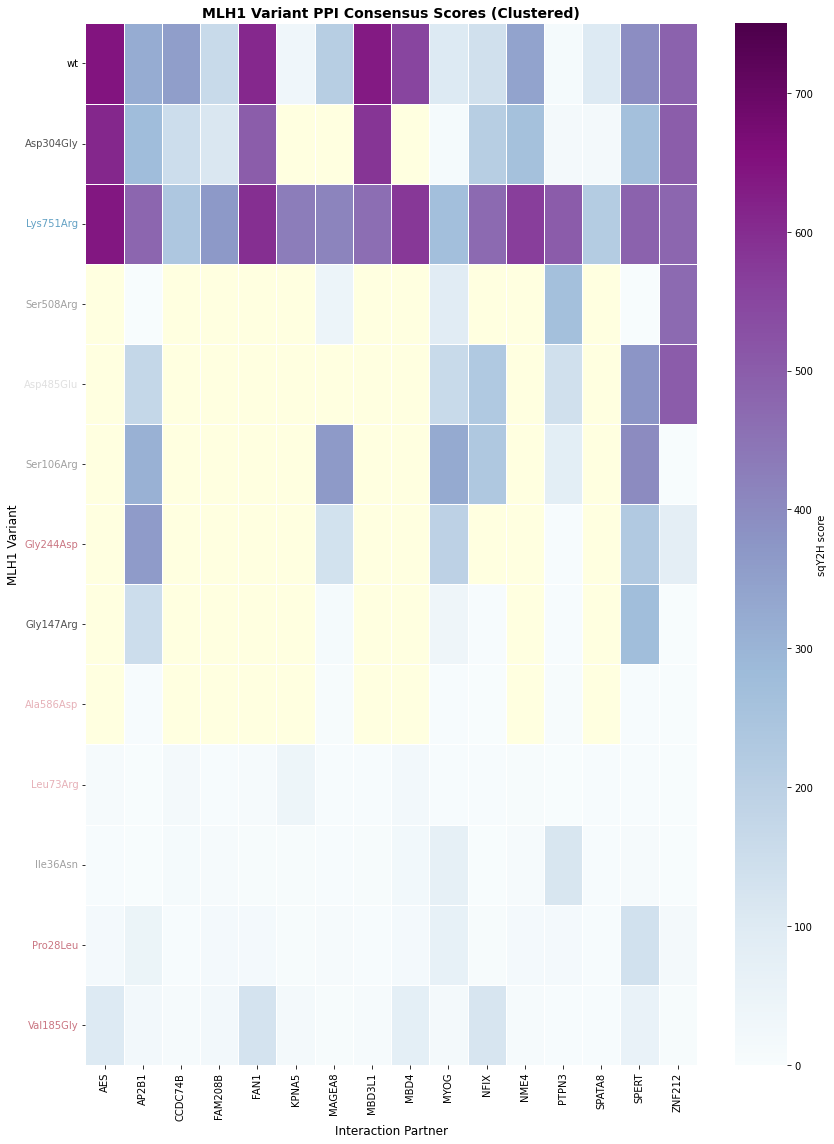

Total MLH1 variants: 13
Total interaction partners: 16
Matrix dimensions: (13, 16)

Missing data: 60 out of 208 total cells

ClinVar classification distribution:
clinvar_clnsig_clean_pp_strict
Pathogenic           3
VUS                  3
Conflicting          2
Likely pathogenic    2
Likely benign        1
Others               1
Name: count, dtype: int64


In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import euclidean

# Pivot the data to create a matrix for the heatmap
# Rows: aa_change (variants), Columns: ad_symbol (partners)
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# Compute pairwise Euclidean distances using only shared non-NaN values
n_variants = len(heatmap_data)
variant_distances = np.zeros((n_variants, n_variants))

for i in range(n_variants):
    for j in range(n_variants):
        row_i = heatmap_data.iloc[i]
        row_j = heatmap_data.iloc[j]
        
        # Find shared non-NaN indices
        shared_mask = ~(row_i.isna() | row_j.isna())
        
        if shared_mask.sum() >= 2:  # Need at least 2 shared points
            dist = euclidean(row_i[shared_mask], row_j[shared_mask])
            variant_distances[i, j] = dist
        else:
            variant_distances[i, j] = 0  # Set to 0 for linkage (will be treated as similar)

# Perform hierarchical clustering on the distance matrix
linkage_matrix = linkage(variant_distances, method='average')
dendro = dendrogram(linkage_matrix, no_plot=True)
clustered_order = dendro['leaves']

# Reorder the heatmap based on clustering
heatmap_data_sorted = heatmap_data.iloc[clustered_order]

heatmap_data_sorted = heatmap_data_sorted.iloc[::-1]

# Sort columns (partners) alphabetically
heatmap_data_sorted = heatmap_data_sorted[sorted(heatmap_data_sorted.columns)]

# Create variant to ClinVar classification mapping
variant_to_clnsig = ppi_edges_mlh1.drop_duplicates('aa_change').set_index('aa_change')['clinvar_clnsig_clean_pp_strict'].to_dict()


# Create the figure
fig, ax = plt.subplots(figsize=(12, 16))

# Create heatmap
sns.heatmap(heatmap_data_sorted, 
            cmap='BuPu',
            vmin=0, 
            vmax=750,
            cbar_kws={'label': 'sqY2H score'},
            linewidths=0.5,
            linecolor='white',
            square=False,
            ax=ax)

ax.set_facecolor('lightyellow')

# Customize labels
ax.set_xlabel('Interaction Partner', fontsize=12)
ax.set_ylabel('MLH1 Variant', fontsize=12)
ax.set_title('MLH1 Variant PPI Consensus Scores (Clustered)', fontsize=14, fontweight='bold')

# Rotate x-axis labels for better readability
plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)

# Color-code y-axis labels by ClinVar classification
for tick_label in ax.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')  # Default to black if not found
    tick_label.set_color(color)

plt.tight_layout()
plt.savefig(f'{output_dir}/MLH1_PPI_heatmap_clustered.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total MLH1 variants: {len(heatmap_data_sorted)}")
print(f"Total interaction partners: {len(heatmap_data_sorted.columns)}")
print(f"Matrix dimensions: {heatmap_data_sorted.shape}")
print(f"\nMissing data: {heatmap_data.isna().sum().sum()} out of {heatmap_data.size} total cells")

# Print ClinVar distribution
print("\nClinVar classification distribution:")
print(ppi_edges_mlh1.drop_duplicates('aa_change')['clinvar_clnsig_clean_pp_strict'].value_counts())

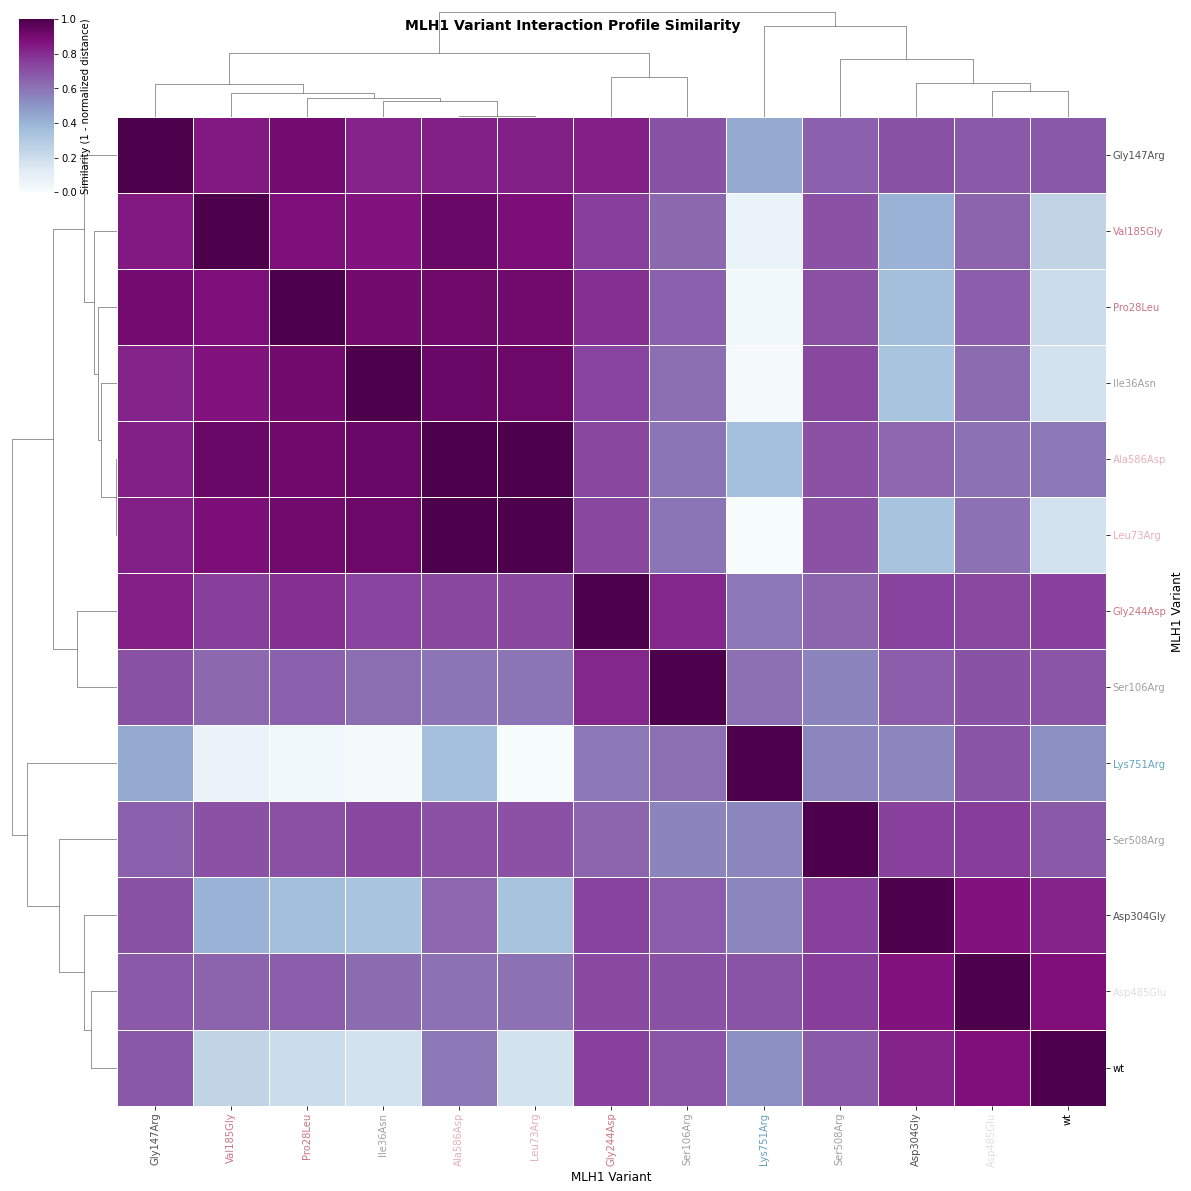

Total MLH1 variants: 13
Matrix dimensions: (13, 13)

Similarity range: 0.000 to 1.000


In [81]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.spatial.distance import euclidean, squareform
from scipy.cluster.hierarchy import linkage

# Pivot the data to create a matrix for the heatmap
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# Compute pairwise Euclidean distances using only shared non-NaN values
n_variants = len(heatmap_data)
variant_distances = np.zeros((n_variants, n_variants))

for i in range(n_variants):
    for j in range(n_variants):
        row_i = heatmap_data.iloc[i]
        row_j = heatmap_data.iloc[j]
        
        # Find shared non-NaN indices
        shared_mask = ~(row_i.isna() | row_j.isna())
        
        if shared_mask.sum() >= 2:  # Need at least 2 shared points
            dist = euclidean(row_i[shared_mask], row_j[shared_mask])
            variant_distances[i, j] = dist
        else:
            variant_distances[i, j] = 0  # No shared data points

# Convert distance matrix to condensed form for linkage
condensed_distances = squareform(variant_distances)

# Perform hierarchical clustering on the distance matrix directly
linkage_matrix = linkage(condensed_distances, method='average')

# Convert distances to similarity for visualization
max_dist = np.max(variant_distances)
variant_similarity = 1 - (variant_distances / max_dist)

# Convert to DataFrame
variant_similarity_df = pd.DataFrame(
    variant_similarity,
    index=heatmap_data.index,
    columns=heatmap_data.index
)

# Create clustered heatmap using pre-computed linkage
g = sns.clustermap(
    variant_similarity_df,
    cmap='BuPu',
    vmin=0,
    vmax=1,
    figsize=(16, 16),
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Similarity (1 - normalized distance)', 'shrink': 0.5},
    dendrogram_ratio=0.1,
    cbar_pos=(0.02, 0.83, 0.03, 0.15),
    row_linkage=linkage_matrix,  # Use pre-computed linkage
    col_linkage=linkage_matrix,  # Same for columns
    row_cluster=True,
    col_cluster=True
)

# Customize axis labels
g.ax_heatmap.set_xlabel('MLH1 Variant', fontsize=12)
g.ax_heatmap.set_ylabel('MLH1 Variant', fontsize=12)

# Rotate labels
plt.setp(g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90, ha='center')
plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

# Color-code y-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)

# Color-code x-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_xticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)


# Add title
g.fig.suptitle('MLH1 Variant Interaction Profile Similarity', 
               fontsize=14, fontweight='bold', y=0.98)

# plt.savefig(f'{output_dir}/MLH1_variant_similarity_clustered.pdf', 
            # format='pdf', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total MLH1 variants: {len(variant_similarity_df)}")
print(f"Matrix dimensions: {variant_similarity_df.shape}")
print(f"\nSimilarity range: {variant_similarity.min():.3f} to {variant_similarity.max():.3f}")

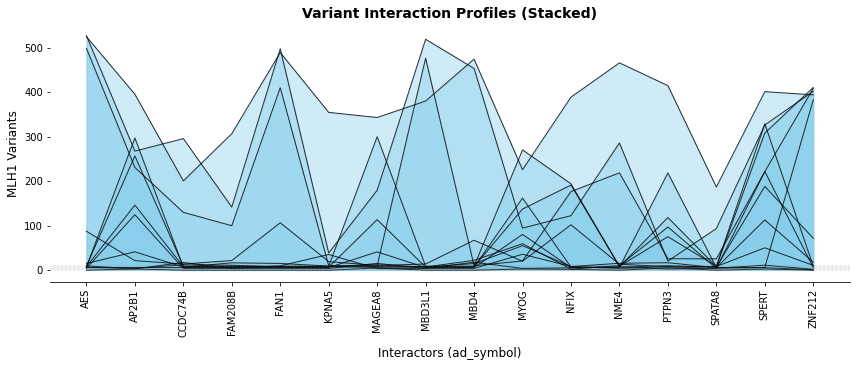

In [89]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Prepare the Data
# We pivot to ensure all variants align on the same x-axis (interactors)
# Filling with 0 is usually necessary for line plots to show "no interaction"
plot_matrix = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score').fillna(0)

# Sort by total signal so the plot looks organized (optional, but recommended)
plot_matrix['total_signal'] = plot_matrix.sum(axis=1)
plot_matrix = plot_matrix.sort_values('total_signal', ascending=True).drop('total_signal', axis=1)

# 2. Setup the Plot
num_variants = len(plot_matrix)
interactors = plot_matrix.columns
x_indices = np.arange(len(interactors))

fig, ax = plt.subplots(figsize=(12, len(plot_matrix) * 0.4)) # Adjust height based on number of variants

# 3. Parameters for the "Ridge" look
row_height = 1.0  # Distance between y-ticks
scale_factor = 0.8 # Scale the interaction peaks so they don't overlap too much

# 4. Plot each variant as a line with an offset
# We iterate in reverse so top variants are at the top of the plot
for i, (variant, row) in enumerate(plot_matrix.iterrows()):
    y_base = i * row_height
    
    # Scale the scores to fit in the row height
    # (row / row.max()) normalizes them 0-1 if you want pure shape comparison
    # But using raw values allows you to see the Euclidean magnitude difference
    y_values = y_base + (row.values * scale_factor)
    
    # Plot the line (The "Shape" - Correlation)
    ax.plot(x_indices, y_values, color='black', linewidth=1, alpha=0.8)
    
    # Fill the area (The "Magnitude" - Euclidean volume)
    ax.fill_between(x_indices, y_base, y_values, color='skyblue', alpha=0.4)
    
    # Add a baseline reference for each variant
    ax.axhline(y_base, color='gray', linestyle=':', linewidth=0.5, alpha=0.3)

# 5. Customize Axes
# ax.set_yticks(np.arange(num_variants) * row_height)
# ax.set_yticklabels(plot_matrix.index, fontsize=10)

ax.set_xticks(x_indices)
ax.set_xticklabels(interactors, rotation=90, ha='center', fontsize=10)

ax.set_xlabel("Interactors (ad_symbol)", fontsize=12, labelpad=10)
ax.set_ylabel("MLH1 Variants", fontsize=12)
ax.set_title("Variant Interaction Profiles (Stacked)", fontsize=14, fontweight='bold')

# Remove top and right spines for a cleaner look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) # Optional: remove box around y-labels

plt.tight_layout()
plt.show()

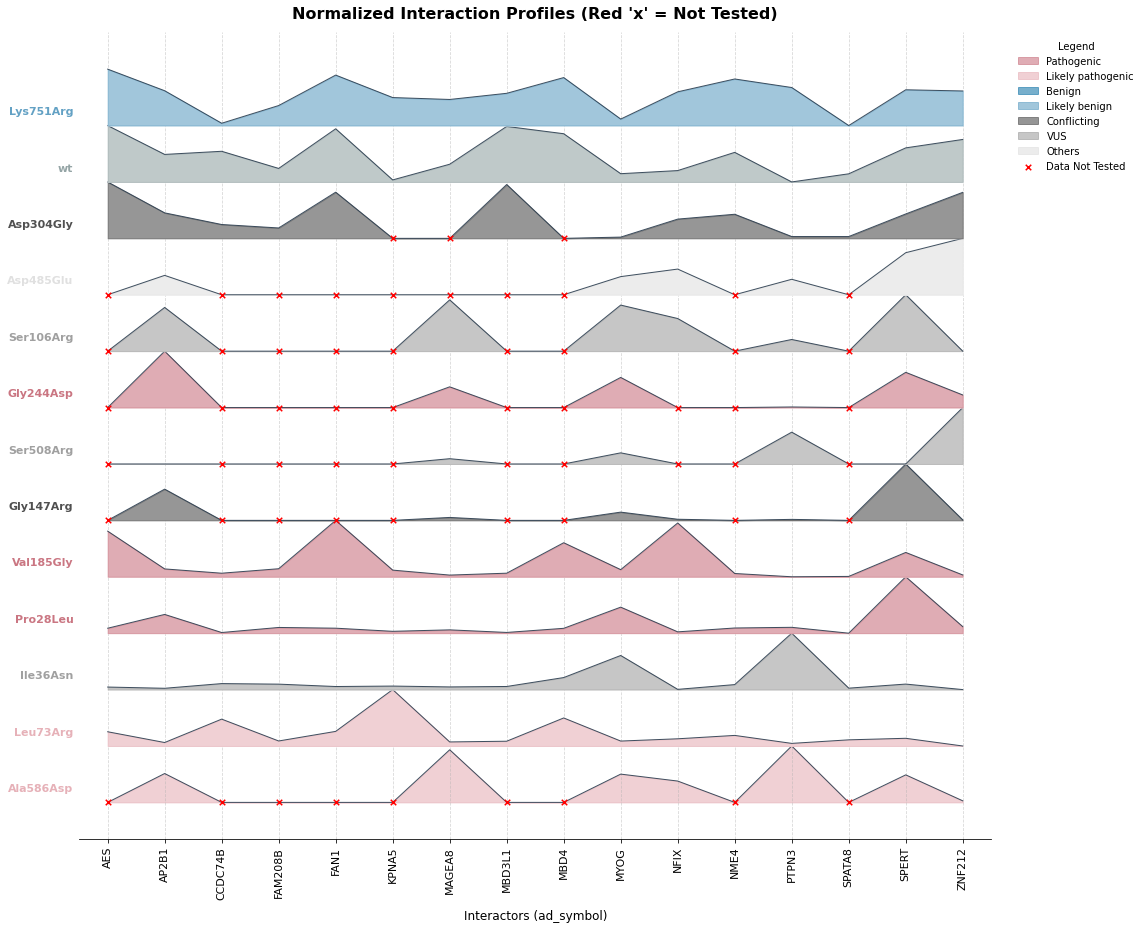

In [118]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# ==========================================
# 0. Setup / Prerequisites
# ==========================================
# Ensure ClinVar dictionaries exist (same as before)
try:
    _ = variant_to_clnsig
    _ = palette_dict['clinvar_clnsig_clean_pp_strict']
except NameError:
    # Dummy placeholders if running outside your full environment
    variant_to_clnsig = {}
    palette_dict = {'clinvar_clnsig_clean_pp_strict': {}}

# ==========================================
# 1. Prepare Data & Identify Missingness
# ==========================================
# 1A. Create raw pivot (with NaNs)
pivot_raw = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# 1B. Create a boolean MASK identifying where data is missing
# True = Missing, False = Present
missing_mask = pivot_raw.isna()

# 1C. Sort rows based on available data mean
# (Using mean of valid data avoids penalizing variants with many NaNs)
pivot_raw['mean_signal'] = pivot_raw.mean(axis=1)
# Sort and drop temp column
pivot_sorted = pivot_raw.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)

# Re-align the missing mask to match the new sorted index
missing_mask_sorted = missing_mask.reindex(pivot_sorted.index)

# ==========================================
# 2. Normalize (Filling with 0 for plotting)
# ==========================================
# Fill NaNs with 0 so we get continuous lines
pivot_filled = pivot_sorted.fillna(0)

scaler = MinMaxScaler()
# Transpose, scale, transpose back
plot_matrix_norm = pd.DataFrame(
    scaler.fit_transform(pivot_filled.T).T,
    index=pivot_filled.index,
    columns=pivot_filled.columns
)

# ==========================================
# 3. Plot Setup
# ==========================================
fig, ax = plt.subplots(figsize=(16, len(plot_matrix_norm) * 1.0))

row_height = 2.0
overlap = 0
scale_factor = row_height + overlap

interactors = plot_matrix_norm.columns
x_indices = np.arange(len(interactors))

# ==========================================
# 4. Plotting Loop (Lines + Missing Markers)
# ==========================================
for i, (variant, row) in enumerate(plot_matrix_norm.iterrows()):
    y_base = i * row_height
    
    # Calculate continuous line values (based on 0-filled data)
    y_values = y_base + (row.values * scale_factor)
    
    # Get ClinVar color
    clnsig = variant_to_clnsig.get(variant, 'Unknown')
    color_hex = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, '#95a5a6')

    # --- Plot Standard Ridge (Continuous Line & Area) ---
    ax.plot(x_indices, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
    ax.fill_between(x_indices, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
    ax.fill_between(x_indices, y_base, y_values, color=color_hex, alpha=0.6, zorder=i*2+1)
    
    # Label
    ax.text(-0.6, y_base + (row_height*0.25), variant,
            fontsize=11, ha='right', va='center', fontweight='bold', color=color_hex)
    
    # --- NEW: Plot Markers for Missing Data ---
    # 1. Get the missing status row corresponding to current variant
    variant_missing_status = missing_mask_sorted.loc[variant]
    
    # 2. Find the X indices where data was originally missing (True in mask)
    missing_x_locs = x_indices[variant_missing_status]
    
    # 3. If there are missing points, plot markers
    if len(missing_x_locs) > 0:
        # Y-coordinates for markers: They should sit right on the baseline (y_base)
        # because we treated them as 0 for the main plot.
        missing_y_locs = np.full(len(missing_x_locs), y_base)
        
        # Scatter plot for marks ('x'). Using a distinct color (e.g., red or black).
        # High zorder ensures they are on top of fills.
        ax.scatter(missing_x_locs, missing_y_locs, 
                   marker='x', color='red', s=30, linewidth=1.5, 
                   zorder=i*2+5, label='Data Not Tested' if i == 0 else "")

# ==========================================
# 5. Final Formatting
# ==========================================
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xticks(x_indices)
ax.set_xticklabels(interactors, rotation=90, ha='center', fontsize=11)
ax.set_xlim(-0.5, len(interactors)-0.5) # Slight padding
ax.set_xlabel("Interactors (ad_symbol)", fontsize=12, labelpad=10)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.title("Normalized Interaction Profiles (Red 'x' = Not Tested)", fontsize=16, y=1.01, fontweight='bold')

# Combine ClinVar legend with the new Missing Data marker
if palette_dict['clinvar_clnsig_clean_pp_strict']:
    # Create handles for ClinVar colors
    clinvar_handles = [plt.Rectangle((0,0),1,1, color=color, label=label, alpha=0.6)
                       for label, color in palette_dict['clinvar_clnsig_clean_pp_strict'].items()]
    
    # Get the handle for the 'x' marker we added to the plot
    handles, labels = ax.get_legend_handles_labels()
    
    # Combine them
    all_handles = clinvar_handles + handles
    
    ax.legend(handles=all_handles, title='Legend',
              bbox_to_anchor=(1.02, 1.0), loc='upper left', frameon=False)

plt.tight_layout()
plt.show()

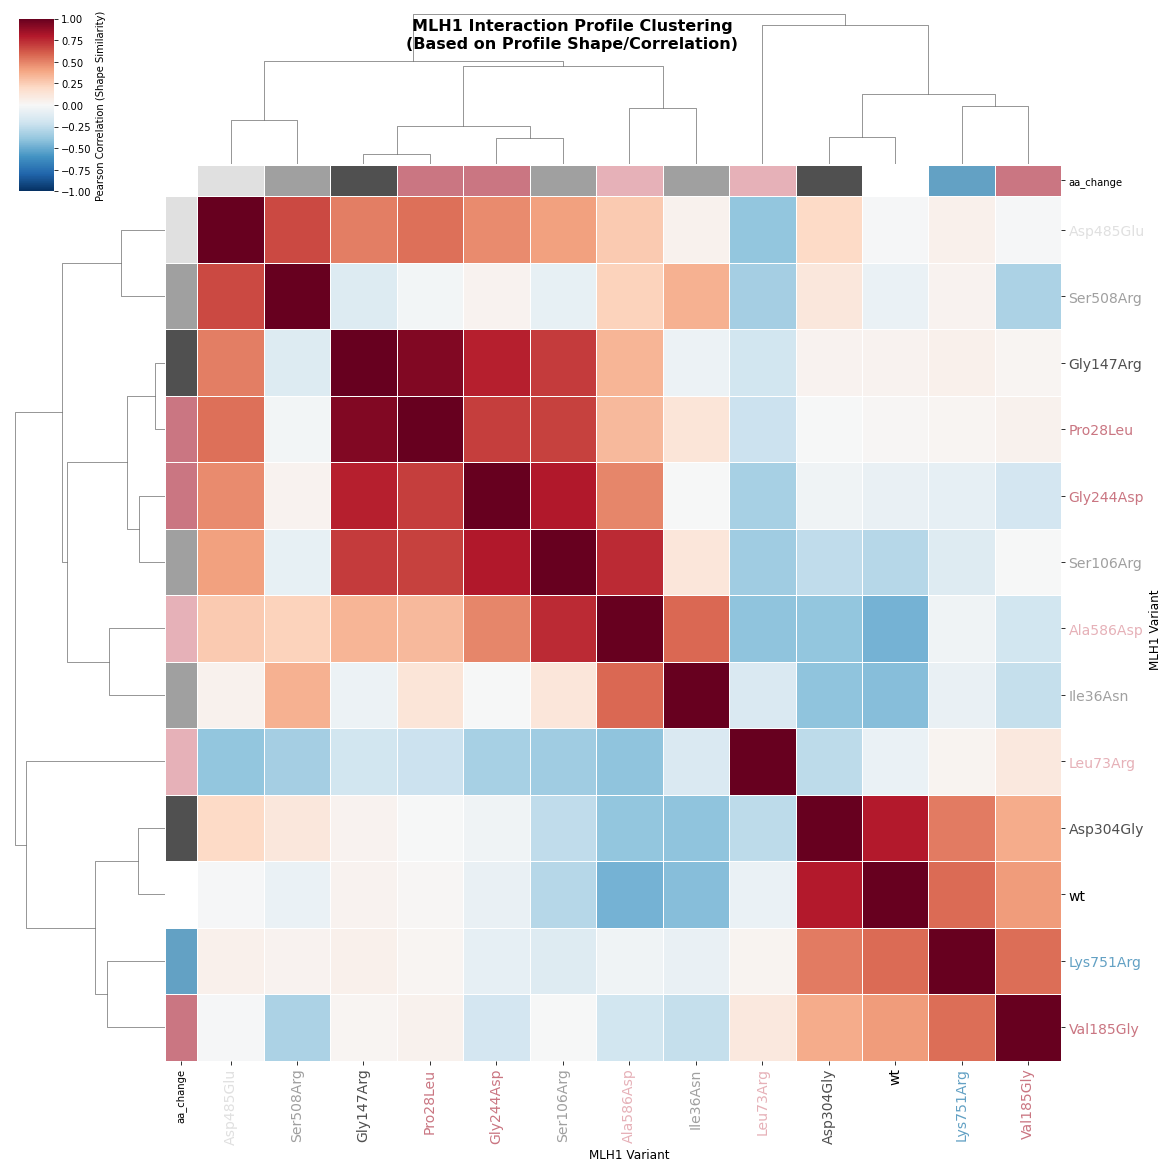

In [95]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage

# 1. Pivot the data
# We fill NaNs with 0 for the correlation calculation to handle missing interactions
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
heatmap_data_filled = heatmap_data.fillna(0)

# 2. Calculate Distance Metric (The "Shape" approach)
# Step A: Calculate Pearson Correlation (1 = identical shape, -1 = opposite)
# We transpose (.T) because .corr() works on columns, and we want variant-to-variant correlation
correlation_matrix = heatmap_data_filled.T.corr(method='pearson')

# Step B: Convert to Distance for Clustering
# Distance must be non-negative.
# d = 1 - r (Range: 0 to 2) -> 0 is identical, 2 is opposite
distance_matrix = 1 - correlation_matrix

# Handle any floating point tiny errors (ensure diagonal is 0)
np.fill_diagonal(distance_matrix.values, 0)
# Fix potential NaNs if a variant had 0 variance (flat line)
distance_matrix = distance_matrix.fillna(1) 

# 3. Perform Hierarchical Clustering
# We use the upper triangle of the distance matrix
condensed_distances = squareform(distance_matrix, checks=False)
linkage_matrix = linkage(condensed_distances, method='average')

# 4. Prepare Side Colors (Restoring your ClinVar coloring)
# We assume 'variant_to_clnsig' and 'palette_dict' exist from your original code.
# If they don't exist in your current session, comment this block out.
try:
    row_colors = pd.Series(heatmap_data.index).map(variant_to_clnsig).map(palette_dict['clinvar_clnsig_clean_pp_strict'])
    row_colors.index = heatmap_data.index
    # You can apply this to columns too if the matrix is symmetric, 
    # but for variant-variant maps, row_colors is usually enough.
except NameError:
    row_colors = None
    print("Note: ClinVar dictionaries not found, skipping label coloring.")


# 5. Generate the Clustermap
# We plot the CORRELATION matrix (heatmap_data is the correlation values themselves)
g = sns.clustermap(
    correlation_matrix,          # Plotting the similarity values (-1 to 1)
    row_linkage=linkage_matrix,  # Use our shape-based clustering
    col_linkage=linkage_matrix,  # Symmetric clustering
    
    # Visualization aesthetics
    cmap='RdBu_r',               # Red (High Sim) <-> Blue (Low Sim)
    center=0,                    # White is 0 correlation
    vmin=-1, vmax=1,             
    
    # Layout
    figsize=(16, 16),
    linewidths=0.5,
    linecolor='white',
    
    # Add the side colors if we successfully created them
    row_colors=row_colors if row_colors is not None else None,
    col_colors=row_colors if row_colors is not None else None,
    
    # Colorbar adjustment
    cbar_kws={'label': 'Pearson Correlation (Shape Similarity)', 'shrink': 0.5},
    cbar_pos=(0.02, 0.83, 0.03, 0.15),
    dendrogram_ratio=0.15
)

# 6. Final Polish
g.ax_heatmap.set_xlabel('MLH1 Variant', fontsize=12)
g.ax_heatmap.set_ylabel('MLH1 Variant', fontsize=12)

# Rotate labels for readability
plt.setp(g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90, ha='center', fontsize=14)
plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0, fontsize=14)


# Color-code y-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)

# Color-code x-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_xticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)


g.fig.suptitle('MLH1 Interaction Profile Clustering\n(Based on Profile Shape/Correlation)', 
               fontsize=16, fontweight='bold', y=0.98)

# plt.savefig('MLH1_correlation_clustering.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

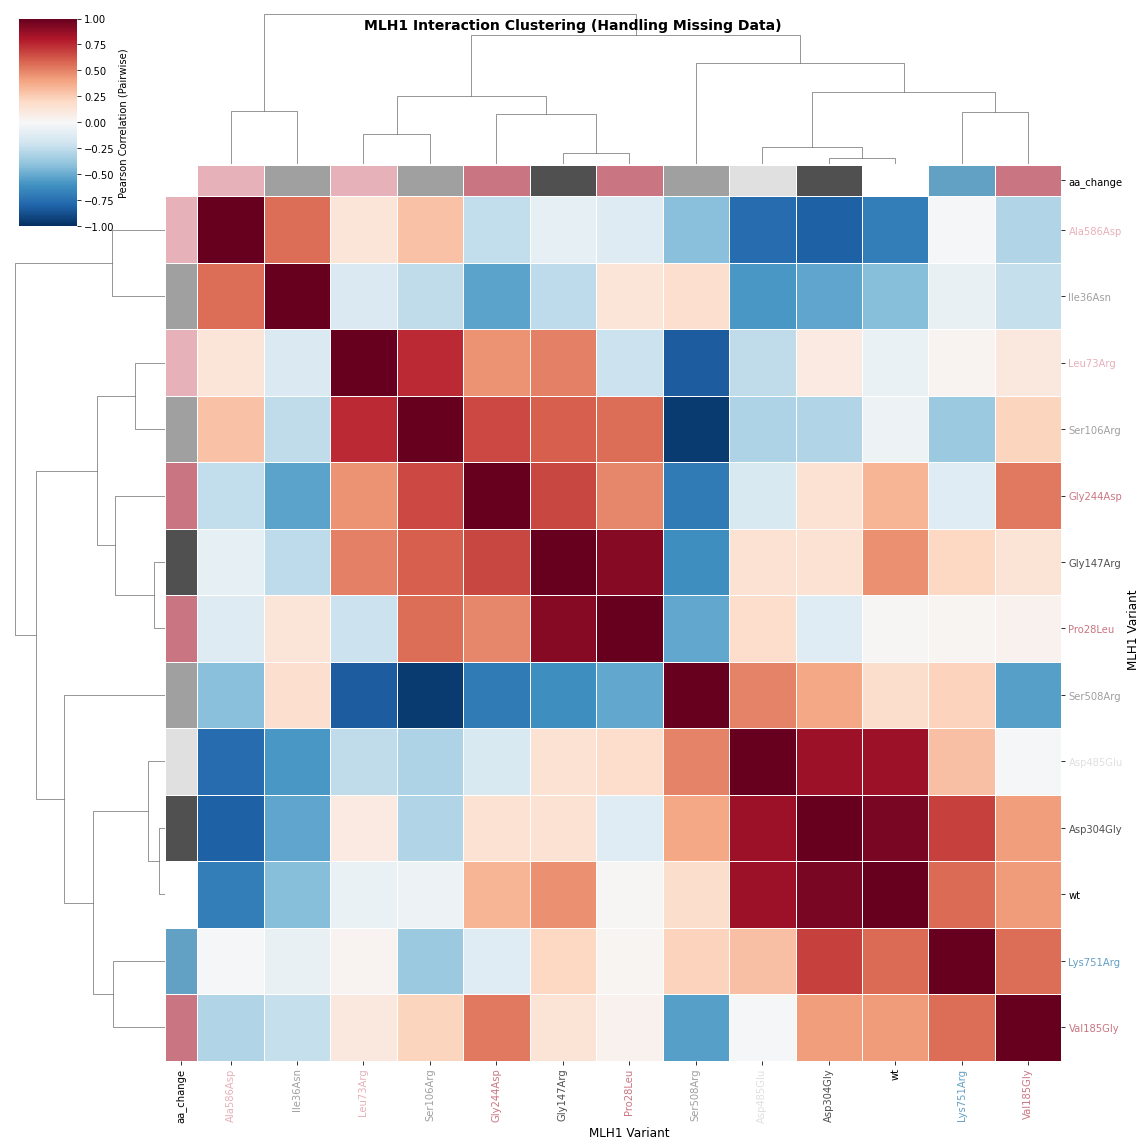

In [112]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage

# 1. Pivot Data (Keep NaNs as NaNs)
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# 2. Calculate Correlation using ONLY mutually observed data
# Pandas .corr() ignores NaNs pairwise automatically.
# min_periods=3 ensures we don't calculate a correlation if they share < 3 data points 
# (Correlation on 2 points is always perfect 1.0 or -1.0, which is noise)
correlation_matrix = heatmap_data.T.corr(method='pearson', min_periods=3)

# 3. Handle Variants with No Overlap
# If Variant A and Variant B share NO common interactors (or < 3), result is NaN.
# We CANNOT fill with 0 (which implies high similarity in distance logic).
# We must fill with 0 correlation (neutral), which converts to Distance = 1.
correlation_matrix_filled = correlation_matrix.fillna(0)

# 4. Convert to Distance
# Distance = 1 - Correlation
# r=1.0 -> d=0.0 (Identical)
# r=0.0 -> d=1.0 (Unrelated/Unknown)
# r=-1.0 -> d=2.0 (Opposite)
distance_matrix = 1 - correlation_matrix_filled

# Ensure strictly symmetric and diagonal is 0
np.fill_diagonal(distance_matrix.values, 0)
# Force symmetry just in case floating point errors crept in
distance_matrix = (distance_matrix + distance_matrix.T) / 2

# 5. Clustering
condensed_distances = squareform(distance_matrix, checks=False)
linkage_matrix = linkage(condensed_distances, method='average')


# 4. Prepare Side Colors (Restoring your ClinVar coloring)
# We assume 'variant_to_clnsig' and 'palette_dict' exist from your original code.
# If they don't exist in your current session, comment this block out.
try:
    row_colors = pd.Series(heatmap_data.index).map(variant_to_clnsig).map(palette_dict['clinvar_clnsig_clean_pp_strict'])
    row_colors.index = heatmap_data.index
    # You can apply this to columns too if the matrix is symmetric, 
    # but for variant-variant maps, row_colors is usually enough.
except NameError:
    row_colors = None
    print("Note: ClinVar dictionaries not found, skipping label coloring.")


# 6. Visualization
# We visualize the correlation matrix (where NaNs are 0/White)
g = sns.clustermap(
    correlation_matrix_filled, 
    row_linkage=linkage_matrix,
    col_linkage=linkage_matrix,
    
    cmap='RdBu_r', 
    center=0,
    vmin=-1, vmax=1,
    
    figsize=(16, 16),
    linewidths=0.5,
    
        # Add the side colors if we successfully created them
    row_colors=row_colors if row_colors is not None else None,
    col_colors=row_colors if row_colors is not None else None,
    
    cbar_kws={'label': 'Pearson Correlation (Pairwise)'},
    dendrogram_ratio=0.15
)

# Labeling
g.ax_heatmap.set_xlabel('MLH1 Variant', fontsize=12)
g.ax_heatmap.set_ylabel('MLH1 Variant', fontsize=12)


# Customize axis labels
g.ax_heatmap.set_xlabel('MLH1 Variant', fontsize=12)
g.ax_heatmap.set_ylabel('MLH1 Variant', fontsize=12)

# Rotate labels
plt.setp(g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90, ha='center')
plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

# Color-code y-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)

# Color-code x-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_xticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)


g.fig.suptitle('MLH1 Interaction Clustering (Handling Missing Data)', y=0.98, fontsize=14, fontweight='bold')

plt.show()